# Fase 1: Entrenamiento del Modelo de Visión
## Problema: Detección de Fatiga en Conductores (Ojos Abiertos vs Cerrados)

**Ficha Técnica de los Datos (Req 4.1):**
* **Origen:** *Driver Drowsiness Dataset (DDD)*, obtenido desde Kaggle. Consiste en recortes de rostros extraídos de videos reales de somnolencia.
* **Clases y Balance:** 2 Clases (`ojos_abiertos`, `ojos_cerrados`). Se balanceó la muestra utilizando 80 imágenes de entrenamiento y 20 de validación por clase.
* **Separación Train/Val:** Se crearon las carpetas manualmente en Google Drive, separando aleatoriamente las imágenes para evitar que el modelo vea en validación datos con los que entrenó.
* **Limitación del Dataset:** Sesgo de iluminación y ángulo. Las imágenes son recortes perfectos; en la vida real, la cámara de la cabina del camión enfrentará sombras, vibraciones o choferes usando lentes de sol.

In [1]:
# Instalamos las librerías necesarias (silenciosamente con -q)
!pip install -q ultralytics transformers datasets scikit-learn

from google.colab import drive
import os
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from transformers import pipeline
from ultralytics import YOLO

# Montamos tu Google Drive
drive.mount('/content/drive')

# Definimos la ruta donde guardaste tus carpetas (Asegúrate de que el nombre coincida)
DATOS = "/content/drive/MyDrive/IA generativa/dataset_fatiga"
CLASES = sorted(os.listdir(f"{DATOS}/train"))
print(f"Clases detectadas en el Drive: {CLASES}")

# Guardamos las rutas de validación para las pruebas finales
val_paths = [(f"{DATOS}/val/{c}/{a}", c) for c in CLASES for a in os.listdir(f"{DATOS}/val/{c}")]
reales = [c for _, c in val_paths]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clases detectadas en el Drive: ['ojos_abiertos', 'ojos_cerrados']


In [2]:
print("--- LÍNEA BASE: CLIP (Sin Entrenar) ---")

# Cargamos el modelo CLIP de Hugging Face usando la GPU (device=0)
clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=0)

# Le damos a CLIP los "prompts" en inglés para que entienda qué buscar
TEXTOS = {
    "ojos_abiertos": "a close up photo of an open eye, awake driver",
    "ojos_cerrados": "a close up photo of a closed eye, sleeping driver",
}
A_CLASE = {v: k for k, v in TEXTOS.items()}

# Hacemos que CLIP prediga las imágenes de validación
preds_clip = [A_CLASE[clip(ruta, candidate_labels=list(TEXTOS.values()))[0]["label"]] for ruta, _ in val_paths]

# Calculamos el accuracy balanceado
acc_clip = balanced_accuracy_score(reales, preds_clip)
print(f"Accuracy balanceada modelo CLIP (Zero-Shot): {acc_clip:.1%}")
print("Nota: Al ser un modelo general, CLIP suele rendir cerca del azar (50%) en problemas médicos/industriales sutiles.")

--- LÍNEA BASE: CLIP (Sin Entrenar) ---


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Accuracy balanceada modelo CLIP (Zero-Shot): 52.5%
Nota: Al ser un modelo general, CLIP suele rendir cerca del azar (50%) en problemas médicos/industriales sutiles.


In [3]:
print("--- ENTRENAMIENTO: YOLO-cls ---")

# Cargamos un modelo YOLO preentrenado pequeñito (nano) para clasificación
# Nota: Si falla la descarga del 26n, puedes cambiarlo por "yolo11n-cls.pt"
yolo = YOLO("yolo26n-cls.pt")

# Entrenamos por 10 épocas con tus imágenes redimensionadas a 128x128
yolo.train(data=DATOS, epochs=10, imgsz=128, plots=True)

--- ENTRENAMIENTO: YOLO-cls ---
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/IA generativa/dataset_fatiga, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=6

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79a7a59a0050>
curves: []
curves_results: []
fitness: 0.9625000059604645
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.925000011920929, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9625000059604645}
save_dir: PosixPath('/content/runs/classify/train')
speed: {'preprocess': 0.001353000001813598, 'inference': 4.108303324997564, 'loss': 7.424999921568087e-05, 'postprocess': 0.00012675000107265078}
top1: 0.925000011920929
top5: 1.0


Accuracy balanceada YOLO: 92.5%


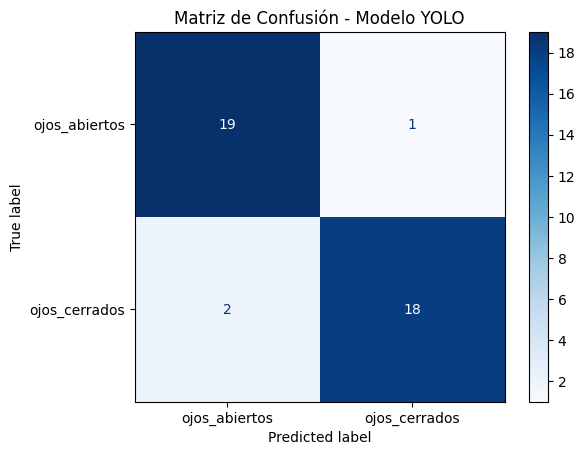


RECALL DE OJOS CERRADOS: 90.0%
--- ANÁLISIS DEL ERROR MÁS COSTOSO ---
Un Falso Positivo (predecir 'ojos cerrados' cuando están abiertos) genera una falsa alarma.
Un Falso Negativo (predecir 'ojos abiertos' cuando están CERRADOS) es un ERROR MORTAL, ya que no se activa la alarma y el chofer puede accidentarse.
Por lo tanto, en producción, el modelo debe optimizarse para maximizar el RECALL de la clase 'ojos_cerrados'.


In [4]:
# Cargamos el mejor modelo que acaba de entrenar YOLO
best_model = YOLO("/content/runs/classify/train/weights/best.pt")

# Obtenemos las predicciones de validación
preds_yolo = []
for ruta, _ in val_paths:
    res = best_model(ruta, verbose=False)[0]
    preds_yolo.append(res.names[res.probs.top1])

# Mostramos las métricas de mejora
acc_yolo = balanced_accuracy_score(reales, preds_yolo)
print(f"\nAccuracy balanceada YOLO: {acc_yolo:.1%}")

# Generamos la Matriz de Confusión
cm = confusion_matrix(reales, preds_yolo, labels=CLASES)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASES)
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Modelo YOLO")
plt.show()

# Cálculo del Recall para Ojos Cerrados (El error más costoso)
idx_cerrados = CLASES.index("ojos_cerrados")
verdaderos_positivos = cm[idx_cerrados, idx_cerrados]
falsos_negativos = cm[idx_cerrados, CLASES.index("ojos_abiertos")]
recall_cerrados = verdaderos_positivos / (verdaderos_positivos + falsos_negativos)

print(f"\nRECALL DE OJOS CERRADOS: {recall_cerrados:.1%}")
print("--- ANÁLISIS DEL ERROR MÁS COSTOSO ---")
print("Un Falso Positivo (predecir 'ojos cerrados' cuando están abiertos) genera una falsa alarma.")
print("Un Falso Negativo (predecir 'ojos abiertos' cuando están CERRADOS) es un ERROR MORTAL, ya que no se activa la alarma y el chofer puede accidentarse.")
print("Por lo tanto, en producción, el modelo debe optimizarse para maximizar el RECALL de la clase 'ojos_cerrados'.")

In [5]:
import shutil

# Copiamos el archivo best.pt directamente a tu carpeta principal de Drive para que te sea fácil descargarlo
ruta_origen = "/content/runs/classify/train/weights/best.pt"
ruta_destino = f"{DATOS}/modelo_fatiga_best.pt"

shutil.copy(ruta_origen, ruta_destino)
print(f"¡Modelo guardado exitosamente en: {ruta_destino}!")
print("Descarga este archivo .pt desde tu Drive, lo necesitaremos para la Fase 2 (app.py).")

¡Modelo guardado exitosamente en: /content/drive/MyDrive/IA generativa/dataset_fatiga/modelo_fatiga_best.pt!
Descarga este archivo .pt desde tu Drive, lo necesitaremos para la Fase 2 (app.py).
